# Task 2 — Explaining household electricity consumption predictions with SHAP

Use SHAP to explain the Main Model overall feature contributions and selected hourly predictions.

**Prediction target:** hourly household electricity consumption, in kWh. 
**Features:** outdoor temperature, hour of day, day of week, and consumption 24 hours earlier. 
**Model:** standardized multiple linear regression, reproduced without changing the Task 1 specification.

The notebook is standalone, and it uses the same datasets and preprocessing choices as Task 1 (model.ipynb).

## 1. Setup and data requirements

Install packages if needed: `pip install numpy pandas matplotlib scikit-learn shap ucimlrepo`.

Place `sceaux_hourly_temperature.csv` in `data/` relative to the notebook. Household power readings are fetched from the UCI repository (dataset ID 235), so the first run requires internet access.

**Assumptions:** 
- Household readings have no explicitly specified timezone; matching them to Open-Meteo timestamps assumes the same clock basis. 
- Temperature is observed at the prediction hour, not a forecast. 

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import display
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

DATA = Path("data")
assert (DATA / "sceaux_hourly_temperature.csv").is_file(), (
    "Place sceaux_hourly_temperature.csv in data/ relative to the notebook."
)
TARGET = "Global_active_power"
FEATURES_MAIN = ["temperature", "hour", "day_of_week", "consumption_lag_24h"]

def scores(y, prediction):
    return {
        "MAE [kWh]": mean_absolute_error(y, prediction),
        "RMSE [kWh]": root_mean_squared_error(y, prediction),
    }

print("SHAP version:", shap.__version__)

/Users/angelina/UHK/Masters Study/UHK2_Sem3/SU/ukol1/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.54.1


## 2. Data loading and feature preparation

Preserved from Task 1: 
- parse minute-level active power (kW)
- aggregate to hourly estimated energy (kWh) only when at least 55 valid minute readings are present
- create the 24-hour lag over a continuous hourly timeline
- merge temperature
- add calendar features. 

Dropping incomplete cases happens after lag creation, so a lag means 24 hours earlier.

With one-minute kW readings, the hourly mean kW is numerically equal to the estimated kWh consumed over a one-hour interval.

In [4]:
# Source loading — equivalent to Task 1, without intermediate audits.
df_consumption = fetch_ucirepo(id=235).data.original.replace(["", "?"], pd.NA)
df_temperature = pd.read_csv(DATA / "sceaux_hourly_temperature.csv")

minute_data = df_consumption[["Date", "Time", TARGET]].copy()
minute_data[TARGET] = pd.to_numeric(minute_data[TARGET], errors="coerce")
minute_data["time"] = pd.to_datetime(
    minute_data["Date"] + " " + minute_data["Time"],
    format="%d/%m/%Y %H:%M:%S",
).dt.floor("h")

# resample creates all intervening hours, including hours without valid readings
hourly = minute_data.set_index("time")[TARGET].resample("h")
valid_measurements = hourly.count()
t = 5 # threshold
total_measurements = 60
consumption_hourly = (
    hourly.mean()
    .where(valid_measurements >= (total_measurements - t))  # same as in task 1
    .rename(TARGET)
    .reset_index()
)
consumption_hourly["consumption_lag_24h"] = consumption_hourly[TARGET].shift(24)

weather = df_temperature.rename(columns={"temperature_2m (°C)": "temperature"}).copy()
weather["time"] = pd.to_datetime(weather["time"])
assert weather["time"].is_unique, "Temperature timestamps must be unique."

df_master = consumption_hourly.merge(
    weather[["time", "temperature"]], on="time", how="left", validate="one_to_one"
)
df_master["hour"] = df_master["time"].dt.hour
df_master["day_of_week"] = df_master["time"].dt.dayofweek  # Monday=0

df_model = df_master.dropna(subset=[TARGET] + FEATURES_MAIN).copy()
assert df_master["time"].is_unique
assert np.isfinite(df_model[FEATURES_MAIN + [TARGET]].to_numpy(dtype=float)).all()
print("Complete usable hours:", len(df_model), "of", len(df_master))
display(df_model[["time"] + FEATURES_MAIN + [TARGET]].head())

/Users/angelina/UHK/Masters Study/UHK2_Sem3/SU/ukol1/.venv/lib/python3.14/site-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (2: Global_active_power, 3: Global_reactive_power, 4: Voltage, 5: Global_intensity, 6: Sub_metering_1, 7: Sub_metering_2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Complete usable hours: 33945 of 34589


,time,temperature,hour,day_of_week,consumption_lag_24h,Global_active_power
25,2006-12-17 18:00:00,4.7,18,6,3.632200,3.697100
26,2006-12-17 19:00:00,4.7,19,6,3.400233,2.908400
27,2006-12-17 20:00:00,4.2,20,6,3.268567,3.361500
28,2006-12-17 21:00:00,3.7,21,6,3.056467,3.040767
29,2006-12-17 22:00:00,3.5,22,6,2.200133,1.518000


## 3. Chronological split and model reproduction

The first 70% of the full hourly timeline is in training, the next 15% is validation, and the final 15% is test. Rows with missing values are removed within these time periods. 

Fit the scaler and regression only on training data, the fitted scaler is then applied to validation and test.

In [6]:
timeline = df_master["time"].sort_values().reset_index(drop=True)
train_end = timeline.iloc[int(len(timeline) * 0.70)]
val_end = timeline.iloc[int(len(timeline) * 0.85)]

train = df_model.loc[df_model["time"] < train_end].sort_values("time").copy()
val = df_model.loc[(df_model["time"] >= train_end) & (df_model["time"] < val_end)].sort_values("time").copy()
test = df_model.loc[df_model["time"] >= val_end].sort_values("time").copy()

assert train["time"].max() < val["time"].min() < test["time"].min()
assert all(part[FEATURES_MAIN + [TARGET]].notna().all().all() for part in (train, val, test))
print("Train / validation / test hours:", len(train), len(val), len(test))

Train / validation / test hours: 23962 5052 4931


Scaler fit on train and model fit. 

In [26]:
scaler_main = StandardScaler().fit(train[FEATURES_MAIN])

def scaled(frame):
    return pd.DataFrame(
        scaler_main.transform(frame[FEATURES_MAIN]),
        index=frame.index, columns=FEATURES_MAIN,
    )

z_train_main, z_val_main, z_test_main = map(scaled, (train, val, test))
y_train, y_val, y_test = (part[TARGET] for part in (train, val, test))

model_main = LinearRegression().fit(z_train_main, y_train)
pred_train_main = model_main.predict(z_train_main)
pred_val_main = model_main.predict(z_val_main)
pred_test_main = model_main.predict(z_test_main)

performance = pd.DataFrame(
    [scores(y_train, pred_train_main), scores(y_val, pred_val_main), scores(y_test, pred_test_main)],
    index=pd.Index(["Train", "Validation", "Test"], name="Split"),
)
display(performance.round(3))

,MAE [kWh],RMSE [kWh]
Split,,
Train,0.605,0.796
Validation,0.603,0.778
Test,0.491,0.636


### Model coefficients (reference for SHAP)

The regression coefficients below represent the prediction change in **kWh per one training-set standard deviation of a feature** (with all other standardized inputs fixed). 

Coefficients show model behavior, not causal effects.

In [27]:
coefficients = pd.DataFrame({
    "Feature": FEATURES_MAIN,
    "Coefficient [kWh / 1 SD]": model_main.coef_,
    "Training mean (original units)": scaler_main.mean_,
    "Training SD (original units)": scaler_main.scale_,
}).set_index("Feature")
display(coefficients.round(4))
print("Intercept [kWh]:", round(float(model_main.intercept_), 4))

,Coefficient [kWh / 1 SD],Training mean (original units),Training SD (original units)
Feature,,,
temperature,-0.1738,11.3687,6.8509
hour,0.2398,11.5010,6.9275
day_of_week,0.0797,2.9965,1.9952
consumption_lag_24h,0.2888,1.0864,0.9285


Intercept [kWh]: 1.0863


## 4. SHAP explanation method

**SHAP (SHapley Additive exPlanations)** assigns a contribution to each feature for a prediction relative to a reference or base value. For any explained hour:

`predicted consumption = base value + sum(feature SHAP values)`

A positive SHAP contribution raises the prediction relative to the base; a negative value lowers it. 

`shap.LinearExplainer` is used on standardized inputs from training. 

**Interpretation note:** This configuration uses an independent-feature / interventional background (the training rows). The features can still be correlated (especially lagged consumption with other features); SHAP values are an allocation of the model prediction and should not be interpreted as causal contributions.

In [23]:
# Use all training rows as the reference background.
background = z_train_main
explainer = shap.LinearExplainer(
    model_main,
    shap.maskers.Independent(background, max_samples=len(background)),
)

# Show the feature means and base prediction actually used by the explainer.
background_means = pd.Series(explainer.mean, index=FEATURES_MAIN, name="Background mean (standardized)")
display(background_means.to_frame().round(6))
print("Base prediction [kWh]:", round(float(explainer.expected_value), 6))

# Explain a representative selection of test hours.
explained_test = z_test_main.sample(n=min(500, len(z_test_main)), random_state=31).sort_index()
shap_values = explainer(explained_test)

# Verify SHAP additivity against the model on the same scaled inputs.
reconstructed = np.asarray(shap_values.base_values) + shap_values.values.sum(axis=1)
np.testing.assert_allclose(reconstructed, model_main.predict(explained_test), rtol=1e-6, atol=1e-6)
print("SHAP explanations:", len(explained_test), "test hours; additivity verified.")

,Background mean (standardized)
temperature,-0.0
hour,0.0
day_of_week,0.0
consumption_lag_24h,-0.0


Base prediction [kWh]: 1.08625
SHAP explanations: 500 test hours; additivity verified.


Background mean is calculated on standardized data, therefore the mean is close to 0.

## 5. Global explainability

Global importance is the **mean absolute SHAP value** across the selected test hours (average of each feature's contribution). 

The **beeswarm plot** adds direction and variation: each dot is one explained hour, and the color reflects its feature value in the representation given to the model. Because features were standardized, the color scale refers to standardized values.

Global SHAP importance is not equal with causality or with the sign of the original feature–target correlation.

,Mean |SHAP| [kWh]
hour,0.2158
consumption_lag_24h,0.1910
temperature,0.1479
day_of_week,0.0700


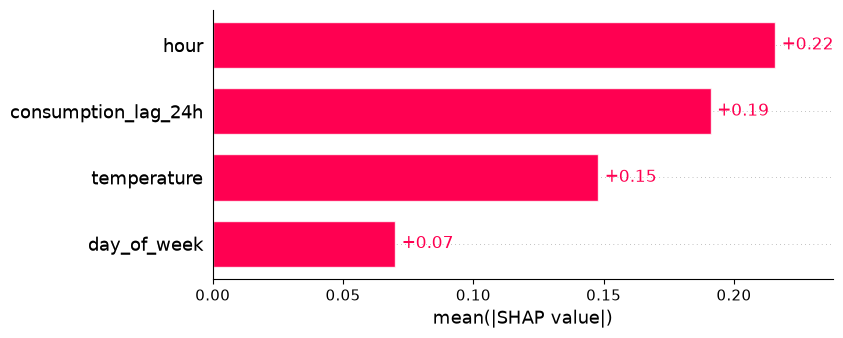

In [28]:
importance = pd.Series(
    np.abs(shap_values.values).mean(axis=0),
    index=FEATURES_MAIN,
    name="Mean |SHAP| [kWh]",
).sort_values(ascending=False)
display(importance.to_frame().round(4))
shap.plots.bar(shap_values, max_display=len(FEATURES_MAIN), show=True)

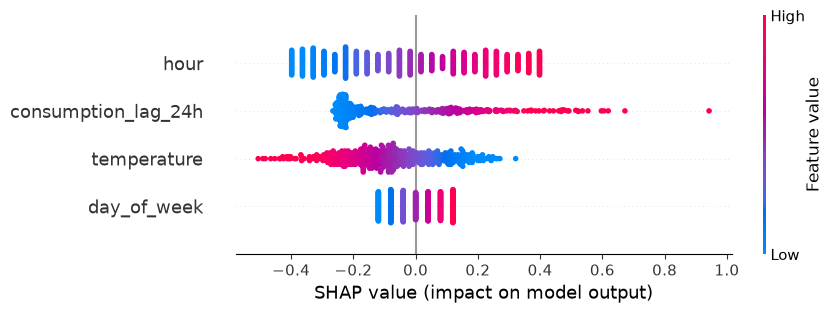

In [29]:
shap.plots.beeswarm(shap_values, max_display=len(FEATURES_MAIN), show=True)

### Feature dependence

This shows how a feature's standardized value relates to its assigned SHAP contribution. In a linear model with an independent-feature reference, the relationship should be linear. This reflects the model's fitted rule.

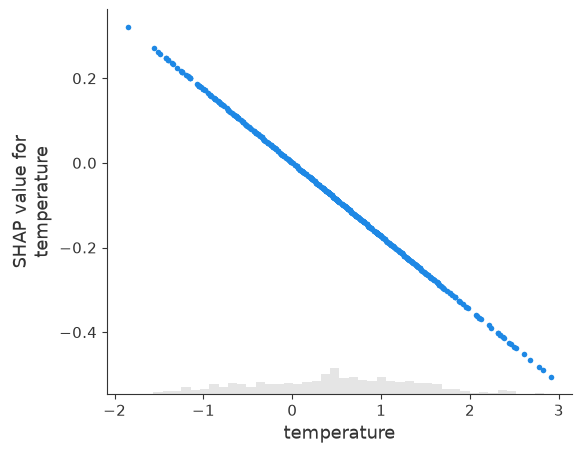

In [30]:
shap.plots.scatter(shap_values[:, "temperature"], show=True)

## 6. Local explainability: individual hours

Two illustrative test predictions are chosen from the explained sample: the highest predicted and the lowest predicted consumption. 

Waterfall charts show how the four features move the prediction upward or downward from the base value. The original (unscaled) feature values are added as well for context.


Highest predicted consumption


/var/folders/qs/d8f7sd3x6gl1p_s9hz43snjh0000gn/T/ipykernel_47733/310941298.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  }]).round(3))


,Timestamp,Actual [kWh],Predicted [kWh],temperature,hour,day_of_week,consumption_lag_24h
0,2010-10-15 19:00:00,1.823,2.338,11.0,19,4,4.118


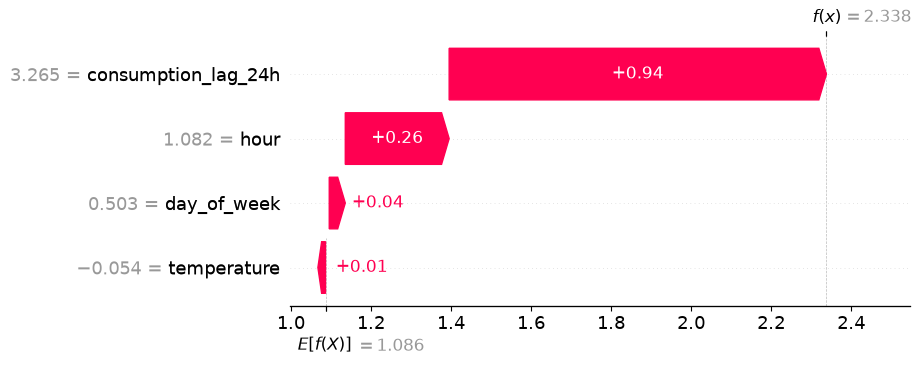


Lowest predicted consumption


/var/folders/qs/d8f7sd3x6gl1p_s9hz43snjh0000gn/T/ipykernel_47733/310941298.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  }]).round(3))


,Timestamp,Actual [kWh],Predicted [kWh],temperature,hour,day_of_week,consumption_lag_24h
0,2010-07-12,1.101,0.079,21.6,0,0,0.348


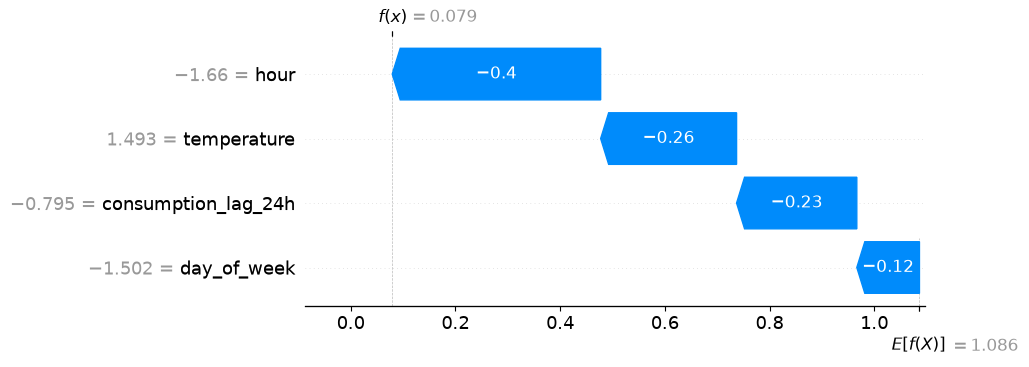

In [31]:
sample_predictions = pd.Series(
    model_main.predict(explained_test), index=explained_test.index,
    name="Predicted [kWh]",
)
selected = {
    "Highest predicted consumption": sample_predictions.idxmax(),
    "Lowest predicted consumption": sample_predictions.idxmin(),
}

for description, row_id in selected.items():
    position = explained_test.index.get_loc(row_id)
    print("\n" + description)
    display(pd.DataFrame([{
        "Timestamp": test.loc[row_id, "time"],
        "Actual [kWh]": test.loc[row_id, TARGET],
        "Predicted [kWh]": sample_predictions.loc[row_id],
        **{feature: test.loc[row_id, feature] for feature in FEATURES_MAIN},
    }]).round(3))
    shap.plots.waterfall(shap_values[position], max_display=len(FEATURES_MAIN) + 1, show=True)